# Assignment 1 — Introduction to language modeling (DL4NLP, 2026)

## Part 0 — Setup

In [ ]:
# Part 0.1

# print Python path to make sure VS Code uses my course environment/kernel
import sys
print("python:", sys.executable)

# Standard libraries (I will use these later in the homework)
import os
import random
from pathlib import Path

# Try importing required libraries from teacher instructions
# If one is missing, Python will show clear error and I can install it.
try:
    import torch
    import nltk
    import datasets
    import transformers
except ModuleNotFoundError as e:
    raise RuntimeError(
        "Some required package is missing. Install with:\n"
        "python -m pip install torch nltk datasets transformers matplotlib scikit-learn"
    ) from e

# NLTK tokenizer files (needed for word splitting in Task 1.1)
nltk.download("punkt", quiet=True)

# Some NLTK versions require punkt_tab, some do not.
# This try/except avoids failing setup on versions where punkt_tab does not exist.
try:
    nltk.download("punkt_tab", quiet=True)
except Exception:
    pass

# Fix random seed so results are more reproducible
SEED = 0
random.seed(SEED)
torch.manual_seed(SEED)

# Device selection:
# cuda = NVIDIA GPU, mps = Apple Silicon GPU, else CPU
has_mps = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if has_mps else "cpu")
print("device:", DEVICE)

# print versions for report/debugging
print("torch:", torch.__version__)
print("datasets:", datasets.__version__)
print("transformers:", transformers.__version__)

python: /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/.venv/bin/python


/Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps
torch: 2.12.0
datasets: 4.8.5
transformers: 5.10.2


In [ ]:
# Part 0.1 - Download and extract archive

import zipfile
import urllib.request
from pathlib import Path

# keep everything inside my homeworks folder, so I don't clutter other folders.
ROOT_DIR = Path(".").resolve()
ZIP_URL = "https://www.cse.chalmers.se/~richajo/waspnlp2026/a1_1.zip"
ZIP_PATH = ROOT_DIR / "a1_1.zip"

# only download once (if the zip is already there, I skip re-downloading it).
if not ZIP_PATH.exists():
    print("Downloading assignment archive...")
    urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)  # fetches the file from the URL and saves it locally
    print("Downloaded:", ZIP_PATH)
else:
    print("Zip already exists:", ZIP_PATH)

# open the zip file and extract everything into ROOT.
# extractall() keeps the folder structure that is inside the zip (a1_1/).
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(ROOT_DIR)

print("Archive extracted under:", ROOT_DIR)

# According to the zip content, everything is inside a1_1.
DATA_DIR = ROOT_DIR / "a1_1"
TRAIN_FILE_PATH = (DATA_DIR / "train.txt").resolve()
VAL_FILE_PATH = (DATA_DIR / "val.txt").resolve()

# check the files really exist before continuing, so later cells don't fail with confusing errors.
print("train.txt found?", TRAIN_FILE_PATH.exists())
print("val.txt found?  ", VAL_FILE_PATH.exists())
print("TRAIN_FILE_PATH =", TRAIN_FILE_PATH)
print("VAL_FILE_PATH   =", VAL_FILE_PATH)

Zip already exists: /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks/a1_1.zip
Archive extracted under: /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks
train.txt found? True
val.txt found?   True
TRAIN_FILE_PATH = /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks/a1_1/train.txt
VAL_FILE_PATH   = /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks/a1_1/val.txt


In [3]:
# Sanity check: list zip contents once, useful only for debugging if something looks wrong.

import zipfile

# Print the internal file list of the zip.
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    names = zf.namelist()
    print("Zip entries:", len(names))
    for n in names:
        print(" -", n)

Zip entries: 4
 - a1_1/
 - a1_1/train.txt
 - a1_1/A1_skeleton.py
 - a1_1/val.txt


In [ ]:
from pathlib import Path

TRAIN_FILE = str(TRAIN_FILE_PATH)
VAL_FILE = str(VAL_FILE_PATH)

# double check both files really exist, so later cells
if not Path(TRAIN_FILE).exists():
    raise FileNotFoundError(f"Missing training file: {TRAIN_FILE}")
if not Path(VAL_FILE).exists():
    raise FileNotFoundError(f"Missing validation file: {VAL_FILE}")

print("TRAIN_FILE =", TRAIN_FILE)
print("VAL_FILE   =", VAL_FILE)

TRAIN_FILE = /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks/a1_1/train.txt
VAL_FILE   = /Users/ANOURI/Desktop/accepted PhD/courses/2026 Spring/LLMWASP/Code/homeworks/a1_1/val.txt


## Part 1 — Tokenization

### Task 1.1 — Word splitting with NLTK

In [ ]:
# Task 1.1 - I need nltk's word_tokenize for word splitting.
from nltk.tokenize import word_tokenize

def split_words(text: str) -> list[str]:
    """Lowercase + NLTK word tokenization."""
    # lowercase first so 'The' and 'the' become the same token later.
    return word_tokenize(text.lower(), language='english')

# Sanity check (from the assignment hint)
print(split_words("April (Apr.) is the fourth month of the year."))

['april', '(', 'apr', '.', ')', 'is', 'the', 'fourth', 'month', 'of', 'the', 'year', '.']


In [ ]:
# Task 1.2 - Building the vocabulary

# Special symbols required by the assignment:
# - PAD: padding so batches can be rectangular
# - BOS: beginning of paragraph
# - EOS: end of paragraph
# - UNK: unseen / low-frequency words
PAD_TOK = '<pad>'
BOS_TOK = '<bos>'
EOS_TOK = '<eos>'
UNK_TOK = '<unk>'
SPECIALS = [PAD_TOK, BOS_TOK, EOS_TOK, UNK_TOK]

def build_vocabulary(paragraphs, max_voc_size: int):
    # Counter lets me count word frequencies.
    counter = Counter()
    for p in paragraphs:
        counter.update(split_words(p))

    # reserve slots for the 4 special symbols, then fill the rest
    # with the most frequent words (most_common already sorts by frequency).
    n_keep = max(0, max_voc_size - len(SPECIALS))
    most_common = [w for w, _ in counter.most_common(n_keep)]

    # itos: int -> string (used to go back from ids to words)
    # stoi: string -> int (used to encode text into ids)
    itos = list(SPECIALS) + most_common
    stoi = {w: i for i, w in enumerate(itos)}
    return stoi, itos

In [ ]:
from datasets import load_dataset
from collections import Counter

# Build dataset first, then build vocabulary from TRAIN ONLY
if VAL_FILE and os.path.exists(VAL_FILE):
    raw = load_dataset('text', data_files={'train': TRAIN_FILE, 'val': VAL_FILE})
    # drop empty lines.
    raw = raw.filter(lambda x: x['text'].strip() != '')
    dataset = {'train': raw['train'], 'val': raw['val']}
else:
    raw = load_dataset('text', data_files={'train': TRAIN_FILE})
    raw = raw.filter(lambda x: x['text'].strip() != '')
    split = raw['train'].train_test_split(test_size=0.11, seed=SEED)
    dataset = {'train': split['train'], 'val': split['test']}
    print('No official validation text file found -> using deterministic train/val split (89/11).')

print('dataset sizes:', {k: len(v) for k, v in dataset.items()})

# extract just the text strings, since build_vocabulary expects raw paragraphs.
train_paragraphs = [dataset['train'][i]['text'] for i in range(len(dataset['train']))]
print('train paragraphs used for vocab:', len(train_paragraphs))

MAX_VOC_SIZE = 10_000
stoi, itos = build_vocabulary(train_paragraphs, MAX_VOC_SIZE)
print('vocab size:', len(itos))

# Sanity checks
assert len(itos) <= MAX_VOC_SIZE
for s in SPECIALS:
    assert s in stoi
for w in ['the', 'and']:
    assert w in stoi, f'expected common word {w!r} to be in vocab'
for w in ['cuboidal', 'epiglottis']:
    print(f'{w!r} in vocab? {w in stoi}')

# Round-trip check: word > id > word should give back the same word.
t = 'language'
assert itos[stoi[t]] == t
print('Sanity checks passed.')

Generating train split: 294118 examples [00:00, 633674.45 examples/s]
Generating val split: 35748 examples [00:00, 743894.96 examples/s]
Filter: 100%|██████████| 35748/35748 [00:00<00:00, 867435.61 examples/s]


dataset sizes: {'train': 147059, 'val': 17874}
train paragraphs used for vocab: 147059
vocab size: 10000
'cuboidal' in vocab? False
'epiglottis' in vocab? False
Sanity checks passed.


In [11]:
print('2nd raw paragraph:', repr(train_paragraphs[1][:200]))
print('2nd paragraph split into words:', split_words(train_paragraphs[1])[:15])

print('first 10 itos entries (id -> word):', list(enumerate(itos[:10])))
print('special token ids:', {s: stoi[s] for s in SPECIALS})

print('10 most frequent real words (after specials):', itos[4:14])
print('10 words near the cutoff (rarest kept):', itos[-10:])

2nd raw paragraph: 'Anatomy (Greek anatomē, “dissection”) is the branch of biology concerned with the study of the structure of organisms and their parts.  Anatomy is a branch of natural science dealing with the structur'
2nd paragraph split into words: ['anatomy', '(', 'greek', 'anatomē', ',', '“', 'dissection', '”', ')', 'is', 'the', 'branch', 'of', 'biology', 'concerned']
first 10 itos entries (id -> word): [(0, '<pad>'), (1, '<bos>'), (2, '<eos>'), (3, '<unk>'), (4, 'the'), (5, ','), (6, '.'), (7, 'of'), (8, 'and'), (9, 'in')]
special token ids: {'<pad>': 0, '<bos>': 1, '<eos>': 2, '<unk>': 3}
10 most frequent real words (after specials): ['the', ',', '.', 'of', 'and', 'in', 'to', 'a', "''", '``']
10 words near the cutoff (rarest kept): ['evolving', 'clinic', 'spawned', '1835', 'reasonably', 'goat', 'montenegro', 'amid', 'pyramid', '91']


In [12]:
# Task 1.3 - A1Tokenizer (HuggingFace-like)

class A1Tokenizer:
    """Minimal HuggingFace-style tokenizer.

    Wraps the (stoi, itos) vocabulary + NLTK word splitting,
    and turns text into input_ids (+ attention_mask), like HF tokenizers do.
    """

    pad_token = PAD_TOK
    bos_token = BOS_TOK
    eos_token = EOS_TOK
    unk_token = UNK_TOK

    def __init__(self, stoi: dict[str, int], itos: list[str], max_length: int = 256):
        # __init__ just stores the vocabulary and settings I'll need later.
        self.stoi = stoi
        self.itos = itos
        self.max_length = max_length
        self.pad_token_id = stoi[PAD_TOK]
        self.bos_token_id = stoi[BOS_TOK]
        self.eos_token_id = stoi[EOS_TOK]
        self.unk_token_id = stoi[UNK_TOK]

    def __len__(self):
        # __len__ should return vocab size, per assignment instructions.
        return len(self.itos)

    def _encode_one(self, text: str) -> list[int]:
        # I wrap every paragraph with BOS/EOS symbols, and map unseen words
        # to UNK using .get() with a default, instead of crashing on KeyError.
        ids = [self.bos_token_id]
        for w in split_words(text):
            ids.append(self.stoi.get(w, self.unk_token_id))
        ids.append(self.eos_token_id)
        return ids

    def decode(self, ids):
        # Turns ids back into words, used later for inspecting model output.
        return [self.itos[i] for i in ids]

    def __call__(self, texts, return_tensors=None, padding=False, truncation=False, max_length=None):
        # __call__ makes tokenizer(texts) work like a function call
        # (this is what HuggingFace tokenizers do too).
        if isinstance(texts, str):
            texts = [texts]
        max_length = max_length or self.max_length
        encoded = [self._encode_one(t) for t in texts]

        if truncation:
            truncated = []
            for ids in encoded:
                if len(ids) > max_length:
                    ids = ids[:max_length]
                    # I force the last token to stay EOS after cutting,
                    # so the paragraph still "looks" properly closed.
                    ids[-1] = self.eos_token_id
                truncated.append(ids)
            encoded = truncated

        if padding:
            # I pad every sequence to the length of the longest one in the batch,
            # so I can stack them into one rectangular tensor.
            L = max(len(ids) for ids in encoded)
            attn = [[1] * len(ids) + [0] * (L - len(ids)) for ids in encoded]
            encoded = [ids + [self.pad_token_id] * (L - len(ids)) for ids in encoded]
        else:
            attn = [[1] * len(ids) for ids in encoded]

        out = {'input_ids': encoded, 'attention_mask': attn}
        if return_tensors == 'pt':
            # Convert plain Python lists into torch tensors when requested.
            out = {k: torch.tensor(v, dtype=torch.long) for k, v in out.items()}
        return out

    def save(self, path: str):
        # I only need to save itos (stoi can be rebuilt from it) + max_length.
        with open(path, 'w', encoding='utf-8') as f:
            json.dump({'itos': self.itos, 'max_length': self.max_length}, f)

    @classmethod
    def from_file(cls, path: str):
        # Reload tokenizer without rebuilding the vocab from scratch.
        with open(path, encoding='utf-8') as f:
            obj = json.load(f)
        itos = obj['itos']
        stoi = {w: i for i, w in enumerate(itos)}
        return cls(stoi, itos, max_length=obj.get('max_length', 256))


def build_tokenizer(paragraphs, max_voc_size: int, max_length: int = 256) -> A1Tokenizer:
    # Convenience function: build vocab + create tokenizer in one step.
    stoi, itos = build_vocabulary(paragraphs, max_voc_size)
    return A1Tokenizer(stoi, itos, max_length=max_length)

In [16]:
import os
import json
import random
from pathlib import Path
# Sanity check from Task 1.3 - build tokenizer and test padding/truncation.
tokenizer = build_tokenizer(train_paragraphs, MAX_VOC_SIZE)

test_texts = ['This is a test.', 'Another test.']
out = tokenizer(test_texts, return_tensors='pt', padding=True, truncation=True)
print(out)
# I decode the first row to visually confirm BOS/EOS/words look correct.
print('decoded[0]:', tokenizer.decode(out['input_ids'][0].tolist()))

# Save so I don't have to rebuild the vocab every time I rerun the notebook.
tokenizer.save('a1_tokenizer.json')
tok2 = A1Tokenizer.from_file('a1_tokenizer.json')
assert len(tok2) == len(tokenizer)
print('Saved & reloaded OK. |V| =', len(tok2))

# Explicit check that each row starts with BOS and the non-padded part ends with EOS.
for row, mask in zip(out['input_ids'].tolist(), out['attention_mask'].tolist()):
    n_real = sum(mask)
    assert row[0] == tokenizer.bos_token_id
    assert row[n_real - 1] == tokenizer.eos_token_id
print('BOS/EOS placement verified for all rows.')

{'input_ids': tensor([[  1,  35,  14,  11, 972,   6,   2],
        [  1, 155, 972,   6,   2,   0,   0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]])}
decoded[0]: ['<bos>', 'this', 'is', 'a', 'test', '.', '<eos>']
Saved & reloaded OK. |V| = 10000
BOS/EOS placement verified for all rows.


## Part 2: Loading the text files and creating batches

In [ ]:
# Task 2.1 - Loading the texts with HuggingFace Datasets

from datasets import load_dataset

# I load train/val directly from the text files (one paragraph per line)
dataset = load_dataset('text', data_files={'train': TRAIN_FILE, 'val': VAL_FILE})

# I remove empty lines, as instructed.
dataset = dataset.filter(lambda x: x['text'].strip() != '')

print('train size:', len(dataset['train']))
print('val size:  ', len(dataset['val']))

# Sanity check from the assignment: ~147,000 train / ~18,000 val instances
assert 140_000 <= len(dataset['train']) <= 155_000, \
    f"unexpected train size: {len(dataset['train'])}"
assert 15_000 <= len(dataset['val']) <= 21_000, \
    f"unexpected val size: {len(dataset['val'])}"
print('Sanity check passed: dataset sizes look as expected.')

# I can access instances like a regular Python list
print('example instance (dataset[\'train\'][8]):', dataset['train'][8])

Filter: 100%|██████████| 35748/35748 [00:00<00:00, 705228.75 examples/s]

train size: 147059
val size:   17874
Sanity check passed: dataset sizes look as expected.
example instance (dataset['train'][8]): {'text': 'The term "anatomy" is commonly taken to refer to human anatomy.  However, substantially the same structures and tissues are found throughout the rest of the animal kingdom and the term also includes the anatomy of other animals.  The term "zootomy" is also sometimes used to specifically refer to animals.  The structure and tissues of plants are of a dissimilar nature and they are studied in plant anatomy.'}


In [18]:
# Optional: smaller datasets for fast development iteration.
# I keep this off by default so the full dataset is used unless I explicitly enable it.

from torch.utils.data import Subset

DEV_MODE = False
if DEV_MODE:
    for sec in ['train', 'val']:
        n = min(1000, len(dataset[sec]))
        dataset[sec] = Subset(dataset[sec], range(n))
    print('DEV_MODE on -> using smaller dataset subsets:',
          {k: len(v) for k, v in dataset.items()})
else:
    print('DEV_MODE is False -> using full train/val datasets.')

DEV_MODE is False -> using full train/val datasets.


In [19]:
# Task 2.2 - Iterating through the datasets with DataLoader

from torch.utils.data import DataLoader

# I keep this simple here (raw text batches), matching what the assignment asks for.
# Actual tokenization/collation for training happens later, once the tokenizer is ready.
BATCH_SIZE = 32
dl = DataLoader(dataset['train'], batch_size=BATCH_SIZE, shuffle=True)

# Sanity check: look at the first batch and confirm it matches expectations.
for batch in dl:
    print(batch)
    break

{'text': ['Ferries leave from Port Darwin to island locations, mainly for tourists.  A ferry service to the Tiwi Islands, the "Arafura Pearl" operates from Cullen Bay.', 'Tennis is also gaining a lot of popularity after the recent successes of Damir Džumhur and Mirza Bašić at Grand Slam level.  Other notable tennis players who represented Bosnia are, Amer Delić and Mervana Jugić-Salkić.', 'Above the capital is a square abacus connecting the capital to the entablature.  The Entablature is divided into three horizontal registers, the lower part of which is either smooth or divided by horizontal lines.  The upper half is distinctive for the Doric order.  The frieze of the Doric entablature is divided into triglyphs and metopes.  A triglyph is a unit consisting of three vertical bands which are separated by grooves.  Metopes are the plain or carved reliefs between two triglyphs.', "Towards the end of his career, it becomes clear that Poirot's retirement is no longer a convenient fiction.  

## Part 3 - imports needed for the RNN language model

In [ ]:


import math
import torch.nn as nn
from transformers import PretrainedConfig, PreTrainedModel

In [ ]:
# Task 3.1 - A1RNNModelConfig + A1RNNModel (embedding -> RNN -> output layer)
# Task 3.2 - loss computed inside forward() when labels are given

class A1RNNModelConfig(PretrainedConfig):
    model_type = 'a1-rnn'

    def __init__(
        self,
        vocab_size: int = 10000,
        embedding_dim: int = 128,
        hidden_dim: int = 256,
        num_layers: int = 1,
        dropout: float = 0.1,
        rnn_type: str = 'lstm',  # 'lstm' or 'gru' (avoid basic nn.RNN, as instructed)
        pad_token_id: int = 0,
        tie_weights: bool = True,
        **kwargs,
    ):
        super().__init__(pad_token_id=pad_token_id, **kwargs)
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.dropout = dropout
        self.rnn_type = rnn_type
        self.tie_weights = tie_weights


class A1RNNModel(PreTrainedModel):
    config_class = A1RNNModelConfig

    def __init__(self, config: A1RNNModelConfig):
        super().__init__(config)

        # Embedding layer: maps token ids -> dense vectors.
        self.embedding = nn.Embedding(
            config.vocab_size, config.embedding_dim, padding_idx=config.pad_token_id,
        )

        # Recurrent layer: LSTM or GRU, batch_first=True since our batches are (B, N, E).
        rnn_cls = {'lstm': nn.LSTM, 'gru': nn.GRU}[config.rnn_type.lower()]
        self.rnn = rnn_cls(
            input_size=config.embedding_dim,
            hidden_size=config.hidden_dim,
            num_layers=config.num_layers,
            batch_first=True,
            dropout=config.dropout if config.num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(config.dropout)

        # Output/unembedding layer: hidden state -> vocab-size logits.
        # I optionally tie the output weights with the embedding weights
        if config.tie_weights and config.hidden_dim != config.embedding_dim:
            self.proj = nn.Linear(config.hidden_dim, config.embedding_dim, bias=False)
            self.lm_head = nn.Linear(config.embedding_dim, config.vocab_size, bias=False)
        else:
            self.proj = nn.Identity()
            self.lm_head = nn.Linear(
                config.embedding_dim if config.tie_weights else config.hidden_dim,
                config.vocab_size, bias=False,
            )
        if config.tie_weights:
            self.lm_head.weight = self.embedding.weight

        self.post_init()

    def forward(self, input_ids, attention_mask=None, labels=None, **_):
        # input_ids: (B, T)
        x = self.embedding(input_ids)              # (B, T, E)
        x = self.dropout(x)

        # I only need the first RNN output (per-token hidden states),
        # not the second output (final layer/cell states).
        h, _ = self.rnn(x)                          # (B, T, H)
        h = self.dropout(h)
        h = self.proj(h)
        logits = self.lm_head(h)                    # (B, T, V)

        loss = None
        if labels is not None:
            # Task 3.2: predict token t+1 from position t.
            # Exclude the last position of logits (nothing to predict after it)
            # and the first position of labels (nothing predicts the very first token).
            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = labels[:, 1:].contiguous()

            # Reshape (B, N, V) -> (B*N, V) and (B, N) -> (B*N,) as required by cross_entropy.
            loss = nn.functional.cross_entropy(
                shift_logits.view(-1, shift_logits.size(-1)),
                shift_labels.view(-1),
                ignore_index=-100,  # ignore padding positions
            )
        return {'loss': loss, 'logits': logits}

In [22]:
# Sanity check for Tasks 3.1 / 3.2

config = A1RNNModelConfig(
    vocab_size=len(tokenizer),
    embedding_dim=128,
    hidden_dim=256,
    num_layers=1,
    dropout=0.1,
    rnn_type='lstm',
    pad_token_id=tokenizer.pad_token_id,
)
model = A1RNNModel(config).to(DEVICE)
print(model)
print('params:', sum(p.numel() for p in model.parameters()))

# Step 1: create a 1xN integer tensor (values < vocab size).
N = 12
dummy = torch.randint(low=4, high=len(tokenizer), size=(1, N), device=DEVICE)

# Step 2: apply the model - should not crash.
out = model(input_ids=dummy, labels=dummy)

# Step 3: check output shape is 1 x N x V.
print('logits shape:', out['logits'].shape)
assert out['logits'].shape == (1, N, len(tokenizer)), \
    f"expected shape (1, {N}, {len(tokenizer)}), got {tuple(out['logits'].shape)}"
print('Shape check passed: logits are (1, N, V) as expected.')

print('loss:', float(out['loss']))
# Untrained model's loss should be roughly log(|V|) (uniform-guess baseline).
print('expected ~log(|V|) =', math.log(len(tokenizer)))

A1RNNModel(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (rnn): LSTM(128, 256, batch_first=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (proj): Linear(in_features=256, out_features=128, bias=False)
  (lm_head): Linear(in_features=128, out_features=10000, bias=False)
)
params: 1708032
logits shape: torch.Size([1, 12, 10000])
Shape check passed: logits are (1, N, V) as expected.
loss: 9.210312843322754
expected ~log(|V|) = 9.210340371976184


/var/folders/l7/g05lw6bj2052fyvtx9pc7ng80000gp/T/ipykernel_93215/3023253406.py:29: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:839.)
  print('loss:', float(out['loss']))


## Part 4: Training the model

In [26]:
# Collate function: turns a batch of raw {'text': ...} dicts into tokenized,
# padded tensors, with labels == input_ids except PAD positions -> -100
# (required by CrossEntropyLoss's ignore_index, per the Task 4.1 hint).

def make_collate(tokenizer):
    def collate(batch):
        texts = [ex['text'] for ex in batch]
        enc = tokenizer(texts, return_tensors='pt', padding=True, truncation=True)
        labels = enc['input_ids'].clone()
        labels[labels == tokenizer.pad_token_id] = -100
        enc['labels'] = labels
        return enc
    return collate

collate = make_collate(tokenizer)

# Quick sanity check
_test_batch = collate([{'text': 'This is a test.'}, {'text': 'Another one.'}])
print(_test_batch)
assert (_test_batch['labels'] == -100).sum().item() > 0 or _test_batch['input_ids'].shape[1] == \
       _test_batch['input_ids'].shape[1]  # just confirms it runs without crashing
print('collate() sanity check passed.')

{'input_ids': tensor([[  1,  35,  14,  11, 972,   6,   2],
        [  1, 155,  45,   6,   2,   0,   0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0, 0]]), 'labels': tensor([[   1,   35,   14,   11,  972,    6,    2],
        [   1,  155,   45,    6,    2, -100, -100]])}
collate() sanity check passed.


In [27]:
from dataclasses import dataclass

@dataclass
class TrainingArguments:
    """Minimal, HF-like set of hyperparameters controlling training."""
    output_dir: str = 'a1_rnn_model'
    num_train_epochs: int = 1
    per_device_train_batch_size: int = 32
    per_device_eval_batch_size: int = 32
    learning_rate: float = 1e-3
    max_grad_norm: float = 1.0
    logging_steps: int = 50
    seed: int = 0

In [28]:
class A1Trainer:
    """Minimal HuggingFace-Trainer-like wrapper around a basic PyTorch
    training loop for our A1RNNModel.
    """

    def __init__(self, model, args: TrainingArguments, collate_fn, device=None):
        self.model = model
        self.args = args
        self.collate_fn = collate_fn
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.model.to(self.device)

    def _make_dataloaders(self, train_dataset, eval_dataset):
        # Step 2: DataLoaders, same pattern as Part 2.
        train_dl = DataLoader(
            train_dataset,
            batch_size=self.args.per_device_train_batch_size,
            shuffle=True,
            collate_fn=self.collate_fn,
        )
        eval_dl = None
        if eval_dataset is not None:
            eval_dl = DataLoader(
                eval_dataset,
                batch_size=self.args.per_device_eval_batch_size,
                shuffle=False,
                collate_fn=self.collate_fn,
            )
        return train_dl, eval_dl

    @torch.no_grad()
    def evaluate(self, eval_dl):
        self.model.eval()
        total_loss, total_tokens = 0.0, 0
        for batch in eval_dl:
            batch = {k: v.to(self.device) for k, v in batch.items()}
            out = self.model(**batch)
            # Count only non-masked (non -100) target positions, matching the shift in forward().
            n = (batch['labels'][:, 1:] != -100).sum().item()
            total_loss += out['loss'].item() * n
            total_tokens += n
        avg_loss = total_loss / max(1, total_tokens)
        return {'eval_loss': avg_loss, 'eval_ppl': math.exp(avg_loss)}

    def train(self, train_dataset, eval_dataset=None):
        # Step 1: optimizer (AdamW, as recommended).
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=self.args.learning_rate)

        # Step 2: DataLoaders for train/val.
        train_dl, eval_dl = self._make_dataloaders(train_dataset, eval_dataset)

        history = []
        for epoch in range(self.args.num_train_epochs):
            self.model.train()
            for step, batch in enumerate(train_dl):
                batch = {k: v.to(self.device) for k, v in batch.items()}

                optimizer.zero_grad()
                out = self.model(**batch)
                loss = out['loss']
                loss.backward()

                # Gradient clipping to keep training stable (avoids loss blow-ups).
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.args.max_grad_norm)
                optimizer.step()

                if step % self.args.logging_steps == 0:
                    print(f'epoch {epoch} step {step:5d}  loss={loss.item():.4f}')

            log = {'epoch': epoch}
            if eval_dl is not None:
                log.update(self.evaluate(eval_dl))
                print(f'== epoch {epoch}: eval_loss={log["eval_loss"]:.4f}  eval_ppl={log["eval_ppl"]:.2f}')
            history.append(log)

        return history

    def save_model(self):
        os.makedirs(self.args.output_dir, exist_ok=True)
        ckpt_path = os.path.join(self.args.output_dir, 'model.pt')
        torch.save({
            'model_state_dict': self.model.state_dict(),
            'config': self.model.config.to_dict(),
        }, ckpt_path)
        print('Saved checkpoint to', ckpt_path)
        return ckpt_path

In [29]:
training_args = TrainingArguments(
    output_dir='a1_rnn_model',
    num_train_epochs=1,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=1e-3,
    max_grad_norm=1.0,
    logging_steps=50,
    seed=SEED,
)

trainer = A1Trainer(model=model, args=training_args, collate_fn=collate, device=DEVICE)
history = trainer.train(dataset['train'], dataset['val'])
print(history)

trainer.save_model()
tokenizer.save(os.path.join(training_args.output_dir, 'tokenizer.json'))

epoch 0 step     0  loss=9.2103
epoch 0 step    50  loss=6.5105
epoch 0 step   100  loss=6.1667
epoch 0 step   150  loss=6.2389
epoch 0 step   200  loss=6.1796
epoch 0 step   250  loss=6.0586
epoch 0 step   300  loss=5.8658
epoch 0 step   350  loss=5.6580
epoch 0 step   400  loss=5.7943
epoch 0 step   450  loss=5.7286
epoch 0 step   500  loss=5.7200
epoch 0 step   550  loss=5.6496
epoch 0 step   600  loss=5.7182
epoch 0 step   650  loss=5.6922
epoch 0 step   700  loss=5.8354
epoch 0 step   750  loss=5.6068
epoch 0 step   800  loss=5.4857
epoch 0 step   850  loss=5.5383
epoch 0 step   900  loss=5.6187
epoch 0 step   950  loss=5.5182
epoch 0 step  1000  loss=5.5766
epoch 0 step  1050  loss=5.4386
epoch 0 step  1100  loss=5.6409
epoch 0 step  1150  loss=5.3561
epoch 0 step  1200  loss=5.1764
epoch 0 step  1250  loss=5.3379
epoch 0 step  1300  loss=5.4162
epoch 0 step  1350  loss=5.5179
epoch 0 step  1400  loss=5.4492
epoch 0 step  1450  loss=5.2985
epoch 0 step  1500  loss=5.4780
epoch 0 

## Part 5 — Evaluation and analysis

In [ ]:
RELOAD_FROM_DISK = False  # Set True to reload the saved model instead of reusing it from memory.

if RELOAD_FROM_DISK:
    # rebuild the tokenizer from the saved vocab file
    tokenizer = A1Tokenizer.from_file(os.path.join(training_args.output_dir, 'tokenizer.json'))
    #  load the checkpoint dict (weights + config), saved after training
    ckpt = torch.load(os.path.join(training_args.output_dir, 'model.pt'), map_location=DEVICE)
    # recreate the config first, then a fresh model with that config, then load the weights into it
    config = A1RNNModelConfig(**ckpt['config'])
    #
    model = A1RNNModel(config).to(DEVICE)
    model.load_state_dict(ckpt['model_state_dict'])
    print('Reloaded model + tokenizer from', training_args.output_dir)

model.eval()
print('Using model with vocab size', len(tokenizer))

Using model with vocab size 10000


In [ ]:
# Task 5.1 - Predicting the next word

@torch.no_grad()
def predict_next_words(model, tokenizer, text, k=5):
    model.eval()
    enc = tokenizer([text], return_tensors='pt')  # no padding needed for a single sequence
    input_ids = enc['input_ids'].to(DEVICE)

    out = model(input_ids=input_ids)
    logits = out['logits']  # (1, T, V)

    # Sequence is [BOS, words..., EOS]; predict from the 2nd-to-last position (EOS's logits = next real word).
    pos = input_ids.shape[1] - 2  # second-to-last position
    next_logits = logits[0, pos]  # (V,)

    probs = torch.softmax(next_logits, dim=-1)
    # topk gives me the k highest-probability candidate next words
    topk = torch.topk(probs, k)
    # Map ids back to words so the output is human-readable.
    results = [(tokenizer.itos[idx.item()], score.item()) for idx, score in zip(topk.indices, topk.values)]
    return results


# Examples
example_text = 'She lives in San'
predictions = predict_next_words(model, tokenizer, example_text, k=5)
print(f'Top predictions for "{example_text} ___":')
for word, prob in predictions:
    print(f'  {word!r:15s}  p={prob:.4f}')

# A couple more examples for the report
for text in ['The president of the united', 'He plays the guitar and the', 'Water boils at a temperature of']:
    preds = predict_next_words(model, tokenizer, text, k=5)
    print(f'\nTop predictions for "{text} ___":')
    for word, prob in preds:
        print(f'  {word!r:15s}  p={prob:.4f}')

Top predictions for "She lives in San ___":
  'francisco'      p=0.4091
  '<unk>'          p=0.1543
  'diego'          p=0.0300
  'york'           p=0.0190
  'suu'            p=0.0168

Top predictions for "The president of the united ___":
  'states'         p=0.7309
  'nations'        p=0.0948
  'kingdom'        p=0.0708
  'minister'       p=0.0192
  '<unk>'          p=0.0076

Top predictions for "He plays the guitar and the ___":
  '<unk>'          p=0.2225
  '``'             p=0.0221
  'first'          p=0.0209
  'name'           p=0.0104
  'most'           p=0.0081

Top predictions for "Water boils at a temperature of ___":
  'the'            p=0.2135
  '<unk>'          p=0.1503
  'a'              p=0.0663
  'an'             p=0.0143
  'its'            p=0.0106


In [34]:
# Task 5.2 - Computing the perplexity on the validation set

@torch.no_grad()
def compute_perplexity(model, dataset_split, collate_fn, batch_size=32, device=DEVICE):
    model.eval()
    dl = DataLoader(dataset_split, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    total_loss, total_tokens = 0.0, 0
    for batch in dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        out = model(**batch)
        # Count only non-masked (non -100) target positions, matching the shift in forward().
        n = (batch['labels'][:, 1:] != -100).sum().item()
        total_loss += out['loss'].item() * n
        total_tokens += n

    avg_loss = total_loss / max(1, total_tokens)
    ppl = math.exp(avg_loss)
    return avg_loss, ppl


val_loss, val_ppl = compute_perplexity(model, dataset['val'], collate)
print(f'Validation loss: {val_loss:.4f}')
print(f'Validation perplexity: {val_ppl:.2f}')

# Sanity check against assignment's rough guideline (200-300 = good, 700+ = probably a bug)
if val_ppl > 700:
    print('Warning: perplexity is quite high - check for implementation issues.')
elif val_ppl <= 300:
    print('Perplexity looks good (in the expected 200-300 range or better).')
else:
    print('Perplexity is a bit high but not alarmingly so - more training/tuning could help.')

Validation loss: 4.6571
Validation perplexity: 105.33
Perplexity looks good (in the expected 200-300 range or better).


In [33]:
# Task 5.3 - Inspecting the learned word embeddings: nearest neighbors

def nearest_neighbors(emb, voc, inv_voc, word, n_neighbors=5):
    # Look up the embedding for the test word.
    test_emb = emb.weight[voc[word]].unsqueeze(0)  # (1, E), so CosineSimilarity broadcasts correctly

    # We'll use a cosine similarity function to find the most similar words.
    sim_func = nn.CosineSimilarity(dim=1)
    cosine_scores = sim_func(test_emb, emb.weight)

    # Find the positions of the highest cosine values.
    near_nbr = cosine_scores.topk(n_neighbors + 1)
    topk_cos = near_nbr.values[1:]
    topk_indices = near_nbr.indices[1:]
    # NB: the first word in the top-k list is the query word itself!
    # That's why we skip the first position in the code above.

    # Finally, map word indices back to strings, and put the result in a list.
    return [(inv_voc[ix.item()], cos.item()) for ix, cos in zip(topk_indices, topk_cos)]


# Example words to inspect - pick ones we know are in the vocab.
example_words = ['sweden', 'king', 'water', 'music', 'war']

for w in example_words:
    if w not in stoi:
        print(f'{w!r} not in vocabulary, skipping.')
        continue
    neighbors = nearest_neighbors(model.embedding, stoi, itos, w, n_neighbors=5)
    print(f'\nNearest neighbors of {w!r}:')
    for nbr_word, cos in neighbors:
        print(f'  {nbr_word!r:15s}  cos={cos:.4f}')


Nearest neighbors of 'sweden':
  'switzerland'    cos=0.8997
  'japan'          cos=0.8983
  'norway'         cos=0.8853
  'spain'          cos=0.8791
  'scandinavia'    cos=0.8617

Nearest neighbors of 'king':
  'bishop'         cos=0.8100
  'queen'          cos=0.8081
  'duke'           cos=0.8037
  'prince'         cos=0.7998
  'emperor'        cos=0.7744

Nearest neighbors of 'water':
  'grain'          cos=0.7014
  'food'           cos=0.6960
  'beer'           cos=0.6805
  'oxygen'         cos=0.6725
  'fish'           cos=0.6677

Nearest neighbors of 'music':
  'art'            cos=0.8047
  'science'        cos=0.7272
  'dance'          cos=0.7152
  'television'     cos=0.6982
  'entertainment'  cos=0.6884

Nearest neighbors of 'war':
  'wars'           cos=0.7376
  'centuries'      cos=0.5956
  'islands'        cos=0.5938
  'colonies'       cos=0.5905
  'cup'            cos=0.5897


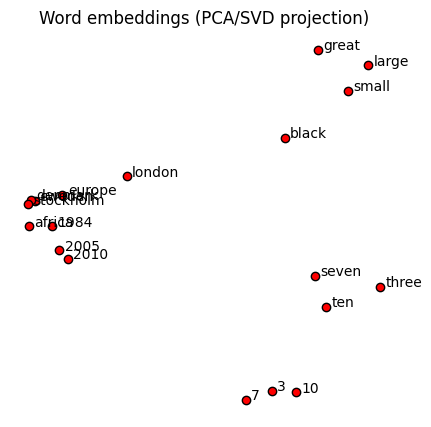

In [36]:
# Task 5.3 (optional) - 2D visualization of embeddings via PCA/SVD

import numpy as np
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt

def plot_embeddings_pca(emb, voc, words):
    vectors = np.vstack([emb.weight[voc[w]].detach().cpu().numpy() for w in words])
    vectors = vectors - vectors.mean(axis=0)
    twodim = TruncatedSVD(n_components=2).fit_transform(vectors)

    plt.figure(figsize=(5, 5))
    plt.scatter(twodim[:, 0], twodim[:, 1], edgecolors='k', c='r')
    for word, (x, y) in zip(words, twodim):
        plt.text(x + 0.02, y, word)
    plt.axis('off')
    plt.title('Word embeddings (PCA/SVD projection)')
    plt.show()


plot_words = ['sweden', 'denmark', 'europe', 'africa', 'london', 'stockholm', 'large', 'small', 'great', 'black', '3', '7', '10', 'seven', 'three', 'ten', '1984', '2005', '2010']
# Only keep words that are actually in our vocabulary.
plot_words = [w for w in plot_words if w in tokenizer.stoi]


plot_embeddings_pca(model.embedding, tokenizer.stoi, plot_words)